Original shape: (3456, 5184, 3)
Original dtype: uint8
Original min/max: 0 255


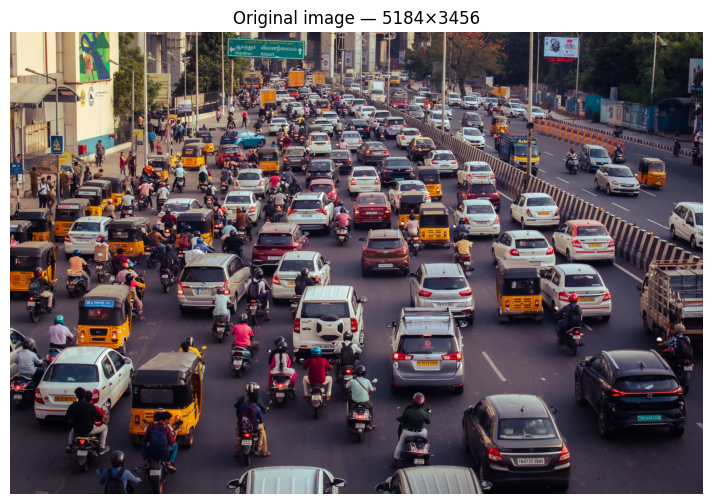

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

img_path = Path("../data/traffic.jpg")
img = cv2.imread(str(img_path))

if img is None:
    raise FileNotFoundError(f"Could not read {img_path.resolve()}")

print("Original shape:", img.shape)
print("Original dtype:", img.dtype)
print("Original min/max:", img.min(), img.max())

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title(f"Original image — {img.shape[1]}×{img.shape[0]}")
plt.axis("off")
plt.show()

In [ ]:
def letterbox(img, new_shape=(640, 640), color=(114, 114, 114)):
    """Resize with aspect ratio preserved and pad to new_shape."""
    shape = img.shape[:2]
    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
    new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
    dw = new_shape[1] - new_unpad[0]
    dh = new_shape[0] - new_unpad[1]
    dw //= 2
    dh //= 2
    if shape[::-1] != new_unpad:
        img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
    img = cv2.copyMakeBorder(img, dh, dh, dw, dw,
                             cv2.BORDER_CONSTANT, value=color)
    return img

resized = letterbox(img, (640, 640))
print("Resized shape:", resized.shape)

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
plt.title(f"Letterboxed — {resized.shape[1]}×{resized.shape[0]}")
plt.axis("off")
plt.show()

Resized shape: (639, 640, 3)


In [4]:
def letterbox(img, new_shape=(640, 640), color=(114, 114, 114)):
    """Resize with aspect ratio preserved and pad to new_shape."""
    shape = img.shape[:2]
    r = min(new_shape[0] / shape[0], new_shape[1] / shape[1])
    new_unpad = (int(round(shape[1] * r)), int(round(shape[0] * r)))
    dw = new_shape[1] - new_unpad[0]
    dh = new_shape[0] - new_unpad[1]
    dw //= 2
    dh //= 2
    if shape[::-1] != new_unpad:
        img = cv2.resize(img, new_unpad, interpolation=cv2.INTER_LINEAR)
    img = cv2.copyMakeBorder(img, dh, dh, dw, dw,
                             cv2.BORDER_CONSTANT, value=color)
    return img

resized = letterbox(img, (640, 640))
print("Resized shape:", resized.shape)
print(resized)

Resized shape: (639, 640, 3)
[[[114 114 114]
  [114 114 114]
  [114 114 114]
  ...
  [114 114 114]
  [114 114 114]
  [114 114 114]]

 [[114 114 114]
  [114 114 114]
  [114 114 114]
  ...
  [114 114 114]
  [114 114 114]
  [114 114 114]]

 [[114 114 114]
  [114 114 114]
  [114 114 114]
  ...
  [114 114 114]
  [114 114 114]
  [114 114 114]]

 ...

 [[114 114 114]
  [114 114 114]
  [114 114 114]
  ...
  [114 114 114]
  [114 114 114]
  [114 114 114]]

 [[114 114 114]
  [114 114 114]
  [114 114 114]
  ...
  [114 114 114]
  [114 114 114]
  [114 114 114]]

 [[114 114 114]
  [114 114 114]
  [114 114 114]
  ...
  [114 114 114]
  [114 114 114]
  [114 114 114]]]


In [8]:
normalized = resized.astype(np.float32) / 255.0
print("Normalized dtype:", normalized.dtype)
print("Normalized shape:", normalized.shape)
print("Normalized min/max:", normalized.min(), normalized.max())

Normalized dtype: float32
Normalized shape: (639, 640, 3)
Normalized min/max: 0.0 1.0


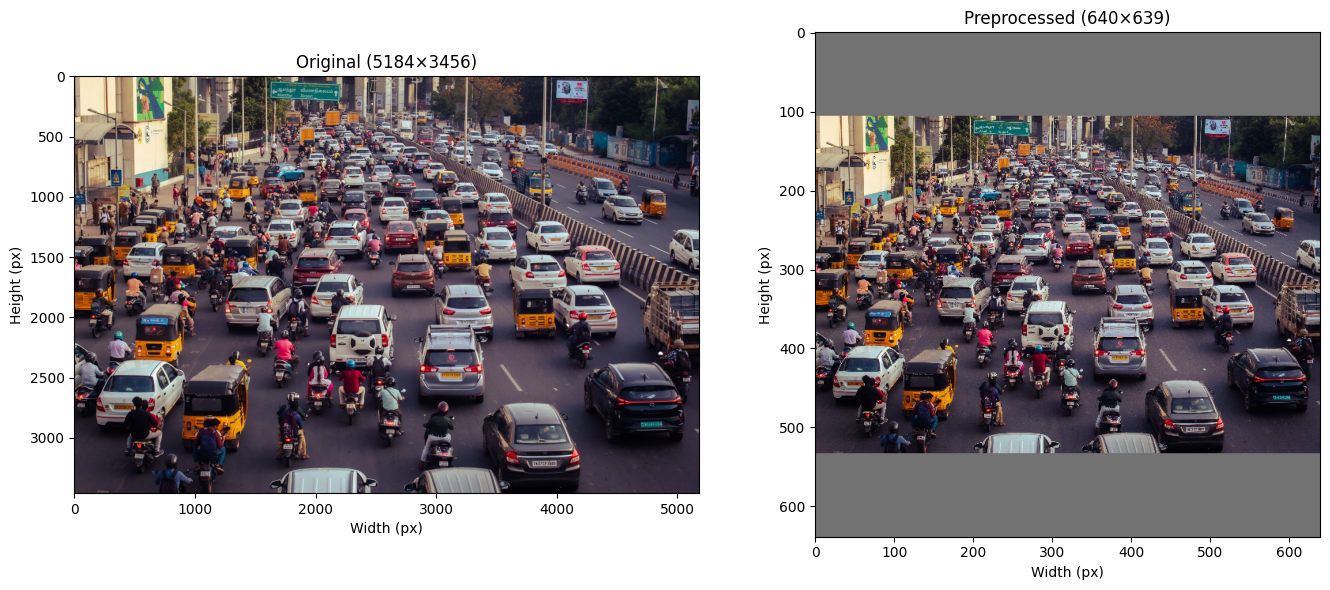

Saved: outputs/task1_preprocessing.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Original ({img.shape[1]}×{img.shape[0]})")
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Height (px)")

axes[1].imshow(cv2.cvtColor(resized, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Preprocessed ({resized.shape[1]}×{resized.shape[0]})")
axes[1].set_xlabel("Width (px)")
axes[1].set_ylabel("Height (px)")

plt.tight_layout()
plt.savefig("../outputs/task1_preprocessing.png", dpi=150)
plt.show()
print("Saved: outputs/task1_preprocessing.png")